# AI 3 · TimesFM: a pretrained foundation model from Hugging Face
**We do NOT train it.** Google trained TimesFM on about **100 billion time points** (web traffic, weather, sales, …).
We download it and use it directly: **zero-shot**.

| | Random Forest / NN | TimesFM |
|---|---|---|
| who trains | we, on AAPL | Google, on 100 B points |
| training time | seconds | weeks on TPUs (Google) |
| our input | 10 hand-made features | the raw price series |
| parameters | ~ thousands | ~ 230 million |

The first run downloads about 900 MB from huggingface.co.

**The task (the same in all four notebooks):** predict tomorrow's Apple (AAPL) closing price.
We test on the **last 60 trading days**, and the model never sees them during training.

**Baseline to beat:** "tomorrow = today". If a model cannot beat this, it has learned nothing useful.

In [1]:
import pandas as pd

prices = pd.read_parquet("../lecture03_datascience/sample/prices_sample.parquet")
aapl = prices[prices["symbol"] == "AAPL"].set_index("date")["close"]
aapl.tail()

date
2025-02-10    227.65
2025-02-11    232.62
2025-02-12    236.87
2025-02-13    241.53
2025-02-14    244.60
Name: close, dtype: float64

## Load the model from Hugging Face

In [2]:
import torch
from transformers import TimesFm2_5ModelForPrediction

model = TimesFm2_5ModelForPrediction.from_pretrained("google/timesfm-2.5-200m-transformers")
model.eval()
print(f"{sum(p.numel() for p in model.parameters()):,} parameters")

/Users/bertram/Projects/github.com/b3rtram/uas_ml/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 272/272 [00:00<00:00, 6717.37it/s]

231,289,280 parameters


## Forecast 20 trading days and compare with the truth
We **hide the last 20 days** from TimesFM. It sees only the 512 prices before them and forecasts 20 days in one go.
Then we compare with what really happened.

Input: just prices. No features, no training.
Output: a **mean forecast** plus **quantiles**: "with 80 % probability the price stays between q10 and q90".

In [3]:
HIDE = 20                                   # days hidden from TimesFM
known = aapl.iloc[:-HIDE]                   # what TimesFM may see
hidden = aapl.iloc[-HIDE:]                  # the truth, only used for comparing

history = torch.tensor(known.values[-512:], dtype=torch.float32)
with torch.no_grad():
    out = model(past_values=[history], forecast_context_len=512)

forecast = pd.Series(out.mean_predictions[0, :HIDE].double().numpy(), index=hidden.index)   # mean forecast
q10 = out.full_predictions[0, :HIDE, 1].numpy()                                    # 10 % quantile
q90 = out.full_predictions[0, :HIDE, 9].numpy()                                    # 90 % quantile
pd.DataFrame({"truth $": hidden, "TimesFM $": forecast}).round(1).head()

,truth $,TimesFM $
date,,
2025-01-17,229.7,228.5
2025-01-21,222.4,227.8
2025-01-22,223.6,227.6
2025-01-23,223.4,228.1
2025-01-24,222.5,227.7


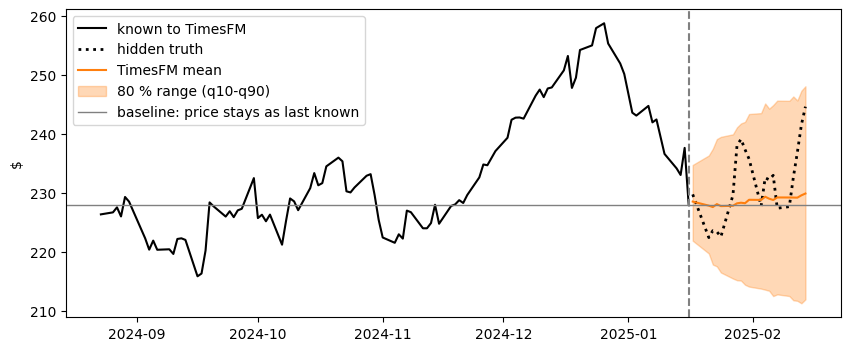

In [4]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(known.iloc[-100:], color="black", label="known to TimesFM")
ax.plot(hidden, color="black", ls=":", lw=2, label="hidden truth")
ax.plot(forecast, color="C1", label="TimesFM mean")
ax.fill_between(hidden.index, q10, q90, color="C1", alpha=0.3, label="80 % range (q10-q90)")
ax.axhline(known.iloc[-1], color="gray", lw=1, label="baseline: price stays as last known")
ax.axvline(known.index[-1], color="gray", ls="--")
ax.set_ylabel("$")
ax.legend();

In [5]:
from sklearn.metrics import mean_absolute_error

flat = np.full(HIDE, known.iloc[-1])                  # baseline: the last known price for all 20 days
inside = ((hidden.values >= q10) & (hidden.values <= q90)).sum()

print(f"MAE baseline 'price stays'  : {mean_absolute_error(hidden, flat):.2f} $")
print(f"MAE TimesFM                 : {mean_absolute_error(hidden, forecast):.2f} $")
print(f"true price inside 80 % range: {inside} of {HIDE} days")

MAE baseline 'price stays'  : 6.00 $
MAE TimesFM                 : 5.59 $
true price inside 80 % range: 20 of 20 days


This is different from the comparison below: here TimesFM gets **no new data** for 20 days, so the band widens with every day.
For a real forecast into the future give it all prices (`aapl.values[-512:]`). Then there is just no truth to compare with yet.

## Fair comparison: the same 60 test days as notebooks 1 and 2
For each test day we give TimesFM the history **up to that day** and take its forecast for the next day.
All 60 histories go into the model in **one batch**.

In [6]:
n = len(aapl)
test_days = aapl.index[n - 61 : n - 1]                 # the 60 test days (same as in notebooks 1 and 2)
histories = [torch.tensor(aapl.values[i - 512 : i], dtype=torch.float32)
             for i in range(n - 60, n)]               # history up to and including each test day

with torch.no_grad():
    out = model(past_values=histories, forecast_context_len=512)
model_price = out.mean_predictions[:, 0].numpy()     # 1-day-ahead forecast

In [7]:
from sklearn.metrics import mean_absolute_error

today = aapl.loc[test_days]
true_price = aapl.shift(-1).loc[test_days]

print(f"MAE baseline 'tomorrow = today': {mean_absolute_error(true_price, today):.2f} $")
print(f"MAE TimesFM (zero-shot)        : {mean_absolute_error(true_price, model_price):.2f} $")

MAE baseline 'tomorrow = today': 2.68 $
MAE TimesFM (zero-shot)        : 2.81 $


Helper: TimesFM's 1-day forecast for each day, converted to a return in % (like the forest and the network predict).

In [8]:
def timesfm_returns(close, days):
    histories = [torch.tensor(close.loc[:day].values[-512:], dtype=torch.float32) for day in days]
    with torch.no_grad():
        out = model(past_values=histories, forecast_context_len=512)
    price_tomorrow = out.mean_predictions[:, 0].numpy()
    return (price_tomorrow / close.loc[days].values - 1) * 100


pred = timesfm_returns(aapl, test_days)
pred[:5].round(3)

array([-0.074, -0.099, -0.147,  0.107, -0.023])

## Would we have made money?
Simple rule with **1 share**: if the model says "up", buy today at the close and sell tomorrow at the close.
If it says "down", do nothing. Compare with **buy & hold**: buy once and keep the share for all 60 days.

In [9]:
import numpy as np

def trading_days(today, tomorrow, pred):
    days = pd.DataFrame({"today $": today.values, "tomorrow $": tomorrow.values}, index=today.index)
    days["model says"] = np.where(pred > 0, "up -> buy", "down -> wait")
    days["profit $"] = np.where(pred > 0, days["tomorrow $"] - days["today $"], 0.0)
    days["running total $"] = days["profit $"].cumsum()
    return days.round(2)


def trading_summary(days):
    bought = days[days["model says"] == "up -> buy"]
    return pd.DataFrame({
        "days bought": [len(bought)],
        "won": [(bought["profit $"] > 0).sum()],
        "lost": [(bought["profit $"] < 0).sum()],
        "model profit $": [days["profit $"].sum()],
        "buy & hold profit $": [(days["tomorrow $"] - days["today $"]).sum()],
    }).round(2)


days = trading_days(today, true_price, pred)
days.head(8)   # the first 8 test days, one row per day

,today $,tomorrow $,model says,profit $,running total $
date,,,,,
2024-11-15,224.75,227.77,down -> wait,0.00,0.00
2024-11-18,227.77,228.03,down -> wait,0.00,0.00
2024-11-19,228.03,228.75,down -> wait,0.00,0.00
2024-11-20,228.75,228.27,up -> buy,-0.48,-0.48
2024-11-21,228.27,229.62,down -> wait,0.00,-0.48
2024-11-22,229.62,232.61,up -> buy,2.99,2.51
2024-11-25,232.61,234.80,up -> buy,2.19,4.70
2024-11-26,234.80,234.67,down -> wait,0.00,4.70


In [10]:
trading_summary(days)

,days bought,won,lost,model profit $,buy & hold profit $
0,35,18,17,-16.43,19.85


## Other stocks
TimesFM was never trained on any of these stocks, not even on AAPL. So for TimesFM, AAPL is just one more stock.
Same 60 test days, same plot, same trading rule as in notebooks 1 and 2.

In [11]:
def apply_timesfm(symbol):
    close = prices[prices["symbol"] == symbol].set_index("date")["close"]
    days = close.index[-61:-1]                      # the same 60 test days as in notebooks 1 and 2

    pred_s = timesfm_returns(close, days)
    today_s = close.loc[days]
    true_s = close.shift(-1).loc[days]
    model_s = today_s * (1 + pred_s / 100)

    print(f"{symbol:<6} MAE baseline 'tomorrow = today': {mean_absolute_error(true_s, today_s):.2f} $")
    print(f"{symbol:<6} MAE TimesFM                    : {mean_absolute_error(true_s, model_s):.2f} $")

    next_day = days + pd.Timedelta(days=1)
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(close.iloc[-120:], color="black", label=f"{symbol} close")
    ax.plot(next_day, today_s, color="gray", lw=3, alpha=0.6, label="baseline: tomorrow = today")
    ax.plot(next_day, model_s, "o-", ms=3, color="C1", label="TimesFM (for next day)")
    ax.axvline(days[0], color="gray", ls="--")
    ax.set_title(f"TimesFM zero-shot on {symbol}")
    ax.set_ylabel("$")
    ax.legend()
    plt.show()
    display(trading_summary(trading_days(today_s, true_s, pred_s)))

MSFT   MAE baseline 'tomorrow = today': 4.25 $
MSFT   MAE TimesFM                    : 4.36 $


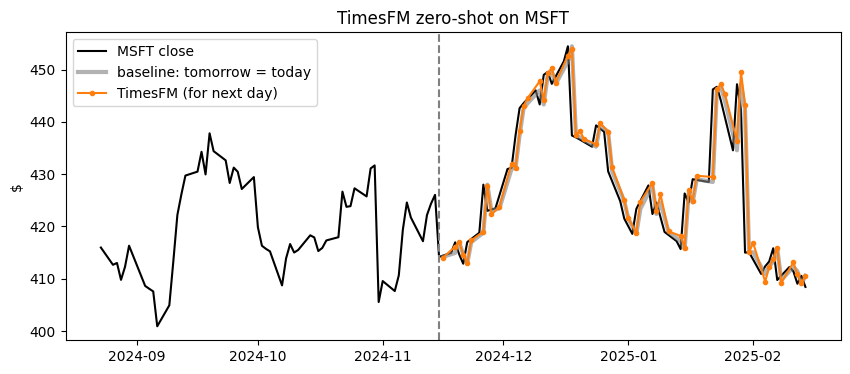

,days bought,won,lost,model profit $,buy & hold profit $
0,49,26,23,24.14,-5.74


In [12]:
apply_timesfm("MSFT")

AMZN   MAE baseline 'tomorrow = today': 2.96 $
AMZN   MAE TimesFM                    : 3.00 $


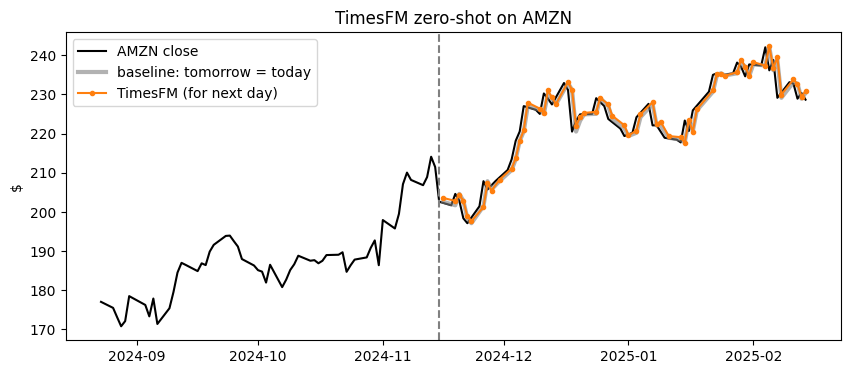

,days bought,won,lost,model profit $,buy & hold profit $
0,49,25,24,14.18,26.07


In [13]:
apply_timesfm("AMZN")

GOOGL  MAE baseline 'tomorrow = today': 2.97 $
GOOGL  MAE TimesFM                    : 2.94 $


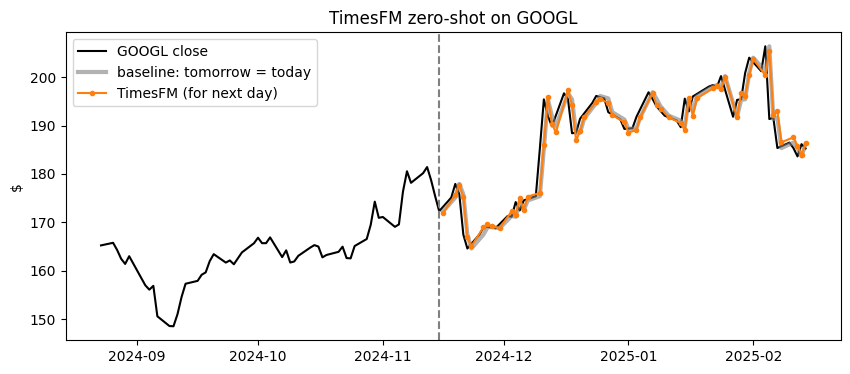

,days bought,won,lost,model profit $,buy & hold profit $
0,29,19,10,38.48,12.94


In [14]:
apply_timesfm("GOOGL")

**Intel (INTC)** for contrast: a stock that **fell** about 60 % in 5 years.

INTC   MAE baseline 'tomorrow = today': 0.47 $
INTC   MAE TimesFM                    : 0.49 $


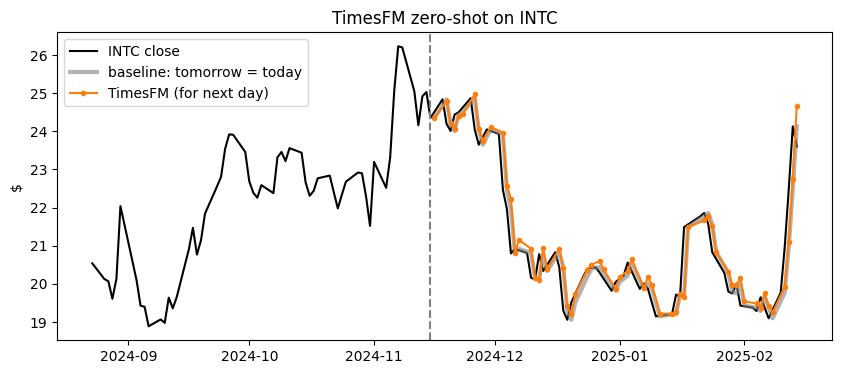

,days bought,won,lost,model profit $,buy & hold profit $
0,48,21,26,-0.64,-0.75


In [15]:
apply_timesfm("INTC")

## Takeaway
- **Two lines** to use a 230-million-parameter model: `from_pretrained` + call it.
- Very useful where time series have patterns (seasons, weekdays, trends: energy, sales, sensors).
- On stock prices it is even a bit **worse** than "tomorrow = today" (2.81 $ vs 2.68 $). Even a huge model cannot predict noise, and it was not trained on our task.
- All three models on the same 60 test days (forest and network trained on AAPL, TimesFM trained by Google):

| stock | MAE baseline | MAE forest | MAE network | MAE TimesFM | profit forest | profit network | profit TimesFM | profit buy & hold |
|---|---|---|---|---|---|---|---|---|
| AAPL | 2.68 $ | 2.54 $ | 2.58 $ | 2.81 $ | +20.52 $ | +16.43 $ | −16.43 $ | +19.85 $ |
| MSFT | 4.25 $ | 4.49 $ | 4.61 $ | 4.36 $ | +11.99 $ | +7.91 $ | +24.14 $ | −5.74 $ |
| AMZN | 2.96 $ | 2.90 $ | 2.96 $ | 3.00 $ | +24.63 $ | +38.00 $ | +14.18 $ | +26.07 $ |
| GOOGL | 2.97 $ | 2.74 $ | 2.92 $ | 2.94 $ | +38.94 $ | +36.46 $ | +38.48 $ | +12.94 $ |
| INTC | 0.47 $ | 0.51 $ | 0.55 $ | 0.49 $ | −5.10 $ | −0.49 $ | −0.64 $ | −0.75 $ |

- The winner changes from stock to stock. No model wins everywhere, and the differences are small compared with the daily moves: **noise, not skill.**
- The **quantile range** is the real added value: it says *how uncertain* the future is.